# E05 · Fourier corrections (variants A, B, C)

`05_fourier_analysis` found one clear difference left between training and Kaggle images after `hist_split`: the
**detail profile** (how much of an image's variation sits in large-scale vs fine patterns). This notebook tests three
ways to remove it, each on top of `E04_contrast_aug` (EfficientNet-B0, 12 bands, `hist_split`, contrast/brightness
augmentation, same hyperparameters) and each with **AdaBN balanced** at the end, as the best setup at the time.

| Variant | Method | Where it acts |
|---|---|---|
| **E05a** | **FDA** (Fourier Domain Adaptation, Yang & Soatto 2020): during training, half of the images get their low-frequency amplitudes (up to 0.05 cycles/pixel) blended with a random Kaggle image's, random weight 0–1; land with land, water with water | training augmentation |
| **E05b** | **Spectral matching**: every training image's radial amplitude spectrum is scaled to the Kaggle average (land and water separately) | data correction (`artifacts/preprocessing/spectral_match.json`) |
| **E05c** | **Low-frequency equaliser**: a fixed first layer scales each image's low-frequency energy towards the training median (max ×1.5) | model input layer |

Code: `src/fourier.py`. Reference: `E04` contrast aug + AdaBN balanced, **68.18%**.

**Train or load.** `LOAD_RUNS` points every variant to its saved run: the notebook loads the weights and
recomputes all results and submission files without training. Set one entry to `None` to train that variant again
(about 25 minutes each on an M4 GPU; creates new run folders).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, adabn_balanced, class_mix, compare_variants, find_run,
                            finish_run, kaggle_monitor, load_experiment_data, load_saved_model,
                            plot_class_mix, plot_variant_curves, pseudo_label_summary,
                            pseudo_labels_from_run, pseudo_labels_from_table, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, adapt_batchnorm, fit, load_run, new_run_dir,
                          predict_proba, predict_views, write_submission)
from src.utils import describe_device, get_device, seed_everything
from src.fourier import FourierDomainAugment, low_freq_energy
apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E05_fourier"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E05a": "runs/2026-10-12_1152_fda_contrast_aug_hist_split_effb0",
    "E05b": "runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0",
    "E05c": "runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0",
}
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)              # all 12 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E04
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

Device: Apple GPU (MPS)


## 2 · E05a · FDA as training augmentation

Blending in a Kaggle image's large-scale amplitudes changes the light/dark patterns of a training image while
keeping its phases (shapes, edges) and its mean.

In [2]:
data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())
FDA = {"radius": 0.05, "p": 0.5, "max_blend": 1.0}

if LOAD_RUNS["E05a"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E05a"], device)
    best_state = None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    fda = FourierDomainAugment(data.kg_images, nir_index=BANDS.index("B08"), **FDA)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer), raw_augment=fda)

results["E05a"] = finish_run(model, normalizer, history, best_state, data, variant="E05a", load_run=LOAD_RUNS["E05a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config={"run_name": "fda_contrast_aug_hist_split_effb0", "description": "E04 + Fourier A: FDA augmentation",
            "notebook": NOTEBOOK, "variant": "E05a", "model": MODEL, "bands": BANDS, "corrections": ["hist_split"],
            "train": asdict(cfg), "split": "split_seed42", "fda": FDA})

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232
Loaded runs/2026-10-12_1152_fda_contrast_aug_hist_split_effb0 (19 epochs): no training


E05a: internal test 98.79% · Kaggle confidence 78.0% (with AdaBN 74.1%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1152_fda_contrast_aug_hist_split_effb0, runs/2026-10-12_1153_adabn_balanced_fda_contrast_aug_hist_split_effb0


## 3 · E05c · Low-frequency equaliser as first layer

Same data as E05a. The layer's target level is the median low-frequency energy of the normalised training images.

In [3]:
if LOAD_RUNS["E05c"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E05c"], device)
    best_state = None
    INPUT_LAYER = json.loads((PROJECT_ROOT / LOAD_RUNS["E05c"] / "config.json").read_text())["input_layer"]
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    X_tr_norm = (data.X_tr[::4].astype(np.float32) - np.array(normalizer.mean, np.float32)[:, None, None]) \
        / np.array(normalizer.std, np.float32)[:, None, None]
    INPUT_LAYER = {"type": "low_freq_equalizer", "radius": 0.05, "max_factor": 1.5,
                   "template": np.median(low_freq_energy(X_tr_norm), axis=0).round(4).tolist()}
    del X_tr_norm
    model = build_model(MODEL, bands=BANDS, pretrained=True, input_layer=INPUT_LAYER).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E05c"] = finish_run(model, normalizer, history, best_state, data, variant="E05c", load_run=LOAD_RUNS["E05c"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config={"run_name": "lowfreq_eq_contrast_aug_hist_split_effb0",
            "description": "E04 + Fourier C: low-frequency equaliser layer", "notebook": NOTEBOOK, "variant": "E05c",
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "input_layer": INPUT_LAYER})

Loaded runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0 (20 epochs): no training


E05c: internal test 98.77% · Kaggle confidence 79.3% (with AdaBN 73.3%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1213_lowfreq_eq_contrast_aug_hist_split_effb0, runs/2026-10-12_1214_adabn_balanced_lowfreq_eq_contrast_aug_hist_split_effb0


## 4 · E05b · Spectral matching of the training images

A second correction after `hist_split`, so the EuroSAT images (including validation and internal test) are reloaded
with both corrections. The Kaggle images stay as they are.

In [4]:
del data
data = load_experiment_data(BANDS, ["hist_split", "spectral_match"], device)

if LOAD_RUNS["E05b"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E05b"], device)
    best_state = None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E05b"] = finish_run(model, normalizer, history, best_state, data, variant="E05b", load_run=LOAD_RUNS["E05b"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config={"run_name": "spectral_contrast_aug_hist_split_effb0",
            "description": "E04 + Fourier B: spectral matching of training images", "notebook": NOTEBOOK,
            "variant": "E05b", "model": MODEL, "bands": BANDS, "corrections": ["hist_split", "spectral_match"],
            "train": asdict(cfg), "split": "split_seed42"})
results = {k: results[k] for k in ("E05a", "E05b", "E05c")}

Loaded runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0 (17 epochs): no training


E05b: internal test 98.57% · Kaggle confidence 79.5% (with AdaBN 72.8%) · 4,022,950 parameters
  run folders: runs/2026-10-12_1130_spectral_contrast_aug_hist_split_effb0, runs/2026-10-12_1131_adabn_balanced_spectral_contrast_aug_hist_split_effb0


## 5 · Comparison

All with AdaBN balanced; reference `E04` contrast aug + AdaBN balanced (68.18%).

In [5]:
REFERENCE = "adabn_balanced_contrast_aug_hist_split_effb0"   # E04 contrast aug + AdaBN balanced, 68.18%
ref_model, ref_norm, _ = load_run(find_run(REFERENCE), device)
views_ref = predict_views(ref_model, data.kg_images, ref_norm)
prob_ref = views_ref.mean(0)
del ref_model

In [6]:
compare_variants(results, reference=prob_ref, reference_name="E04").round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E04 (%),Kaggle public (%)
E05a,E04 + Fourier A: FDA augmentation,98.790123,74.090256,71.668242,87.334594,66.261
E05b,E04 + Fourier B: spectral matching of training...,98.567901,72.755066,70.888469,90.170132,67.852
E05c,E04 + Fourier C: low-frequency equaliser layer,98.765432,73.264221,72.093573,89.413989,67.898


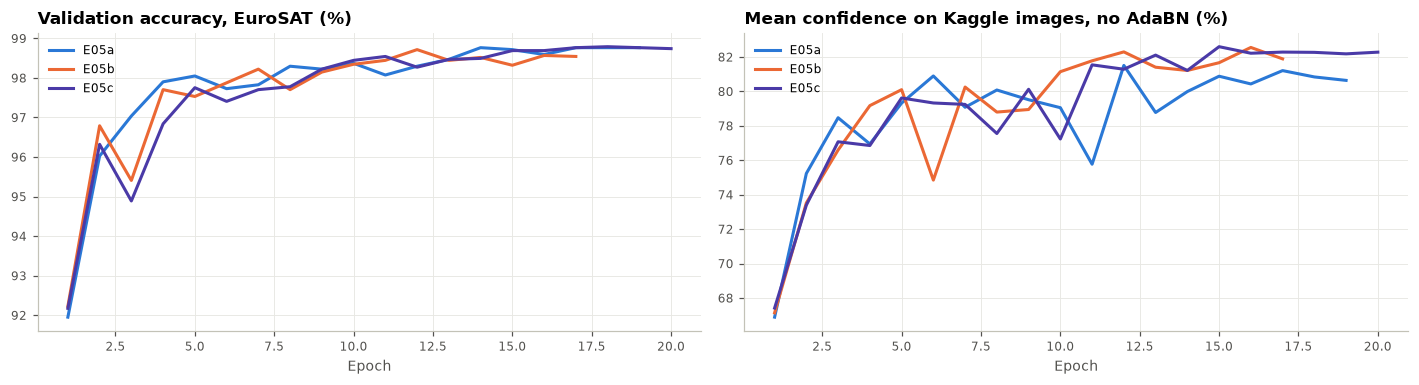

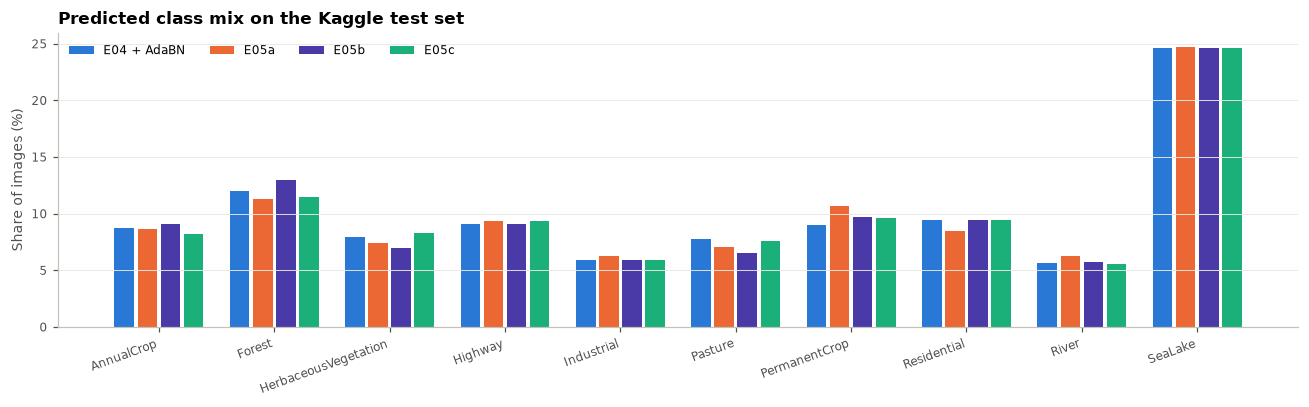

In [7]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"E04 + AdaBN": class_mix(prob_ref), **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 6 · Conclusion

| Variant | Kaggle public (with AdaBN) | vs E04 + AdaBN (68.18%) |
|---|---|---|
| E05a FDA | 66.26% | −1.9 |
| E05b spectral matching | 67.85% | −0.3 |
| E05c low-frequency equaliser | 67.90% | −0.3 |

- **FDA lowered the score.** Blending in a random Kaggle image's large-scale amplitudes creates unrealistic blotchy
  patterns (`05_fourier_analysis`, section 6). With contrast augmentation already covering contrast variation, FDA mainly adds noise.
- **Spectral matching removed almost the whole measured spectrum difference (gap 0.146 → 0.020) without raising the
  score.** The difference is easy for a classifier to *detect*, but the CNN apparently already ignores it: a harmless
  difference, not a cause of the remaining errors.
- **The equaliser layer is neutral.** It removes large-scale contrast differences by design, but also some real
  information (uniform vs patchy areas), and AdaBN already handles most of the contrast shift.

The public leaderboard uses about half of the 4,232 test images, so differences below about 1 point (roughly 20 images)
are within noise. **Lesson:** the spectrum difference is detectable but not decision-relevant; none of the three is kept.